# Análise pré-modelagem — vazão diária USGS

**Objetivo.** Diagnosticar a base compartilhada (`serie`) **antes** de treinar os três modelos (GP Student‑t, RGP‑t, GPLVM). O notebook responde cinco perguntas:

1. A base está íntegra e livre de vazamento (splits, máscara, normalização)?
2. Qual a qualidade dos dados (faltantes, lacunas, zeros)?
3. Como estão os rótulos de anomalia (quantidade, concentração, estabilidade no tempo)?
4. Quais estruturas os modelos precisam capturar (assimetria, deriva, sazonalidade, dependência entre estações)?
5. A avaliação tem poder estatístico suficiente no teste?

Usa somente `src/` (sem alterar nada) e **não imputa** dados: onde um diagnóstico exige série contínua (periodograma), a interpolação é usada só para o gráfico e nunca volta para a base.

## 1. Imports e raiz do projeto

In [4]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.main import SelectionConfig, SplitConfig, build_model_dataset
from src.model_data import SPLITS as ORDEM_SPLITS, split_summary
from src.model_inputs import gplvm_inputs, windows_to_days

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Raiz do projeto:", ROOT)

Raiz do projeto: c:\Users\kayla\Meu Drive (kaylany.meneses18@gmail.com)\usgs_streamflow


## 2. Configuração
`SELECAO` e `SPLITS` são **lidos do `notebooks/construcao_bases_modelos.ipynb`**, para esta análise usar exatamente a mesma base dos modelos (sem duplicar valores). Se o arquivo não existir ou as definições não forem encontradas, usa os valores padrão abaixo e avisa. Os dados em si são localizados por `build_model_dataset` (via `src/config.py`), sem caminhos manuais.

In [5]:
import ast, json

NB_BASES = ROOT / "notebooks" / "construcao_bases_modelos.ipynb"
USAR_NOTEBOOK_BASES = True      # False = usar só os valores padrão abaixo

# valores padrão (usados se a leitura do notebook de bases falhar)
SELECAO = SelectionConfig(n_sensors=200, min_completeness=0.95, max_zero_frac=0.05, seed=42)
SPLITS = SplitConfig(fracs=(0.60, 0.15, 0.10, 0.15), hidden_frac=0.10, hidden_block_len=1,
                     log_transform=True, seed=42)

def ler_config(caminho, nome):
    # devolve o valor da ÚLTIMA atribuição `nome = Classe(...)` nas células de código
    achado = None
    for c in json.loads(caminho.read_text(encoding="utf-8"))["cells"]:
        if c["cell_type"] != "code":
            continue
        try:
            arvore = ast.parse("".join(c["source"]))
        except SyntaxError:     # células com magics (%, !) são ignoradas
            continue
        for no in arvore.body:
            if isinstance(no, ast.Assign) and any(isinstance(t, ast.Name) and t.id == nome for t in no.targets):
                achado = ast.Expression(no.value)
    if achado is None:
        raise KeyError(f"{nome} não encontrado em {caminho.name}")
    codigo = compile(ast.fix_missing_locations(achado), "<notebook_bases>", "eval")
    return eval(codigo, {"SelectionConfig": SelectionConfig, "SplitConfig": SplitConfig})

origem = "valores padrão deste notebook"
if USAR_NOTEBOOK_BASES:
    try:
        SELECAO, SPLITS = ler_config(NB_BASES, "SELECAO"), ler_config(NB_BASES, "SPLITS")
        origem = f"{NB_BASES.relative_to(ROOT)}"
    except Exception as erro:
        print(f"AVISO: não consegui ler {NB_BASES.name} ({erro}). Usando valores padrão.")
print("Origem da configuração:", origem)
print(SELECAO)
print(SPLITS)

# parâmetros apenas desta análise
JANELAS = (7, 14, 30)                 # tamanhos de janela do GPLVM a comparar
LAGS = (1, 7, 30, 182, 365)           # defasagens da autocorrelação (dias)
PERIODO_MIN, PERIODO_MAX = 2, 800     # faixa de períodos do periodograma (dias)
LIM_EXTREMO = 4.0                     # |y| acima disso conta como valor extremo
MIN_ANOM_TESTE = 100                  # mínimo desejável de dias anômalos no teste
MIN_EST_ANOM_TESTE = 10               # mínimo desejável de estações com anomalia no teste

Origem da configuração: notebooks\construcao_bases_modelos.ipynb
SelectionConfig(n_sensors=200, min_completeness=0.95, max_zero_frac=0.05, candidates=None, seed=42)
SplitConfig(fracs=(0.6, 0.15, 0.1, 0.15), hidden_frac=0.1, hidden_block_len=1, log_transform=True, seed=42)


## 3. Carga da base e verificações de integridade

In [6]:
serie, stats = build_model_dataset(SELECAO, SPLITS)
serie["sensor_id"] = serie["sensor_id"].astype(str)

ORDEM = list(ORDEM_SPLITS)
SENSORES = sorted(serie["sensor_id"].unique())
N_EST, N_DIAS = len(SENSORES), serie["t"].nunique()

print(f"Linhas: {len(serie):,} | estações: {N_EST} | dias por estação: {N_DIAS}")
print(f"Período: {serie['data'].min():%Y-%m-%d} a {serie['data'].max():%Y-%m-%d}")
serie.head()

Linhas: 1,168,800 | estações: 200 | dias por estação: 5844
Período: 2010-01-01 a 2025-12-31


,sensor_id,t,data,split,y_bruto,y,observado,escondido_aval,visivel,aprovacao,qualificador,anomalia
0,USGS-04010500,0,2010-01-01,treino,94.0,-1.056399,1,0,1,Approved,ESTIMATED,0
1,USGS-04010500,1,2010-01-02,treino,88.8,-1.110709,1,0,1,Approved,ESTIMATED,0
2,USGS-04010500,2,2010-01-03,treino,87.6,-1.123688,1,0,1,Approved,ESTIMATED,0
3,USGS-04010500,3,2010-01-04,treino,87.1,-1.129149,1,0,1,Approved,ESTIMATED,0
4,USGS-04010500,4,2010-01-05,treino,86.5,-1.135742,1,0,1,Approved,ESTIMATED,0


Cada linha abaixo é uma regra que a base precisa cumprir. Se alguma falhar, a execução **para aqui**: não vale analisar nem modelar uma base inconsistente.

In [7]:
checks = []
def chk(nome, ok, detalhe=""):
    checks.append({"verificação": nome, "ok": bool(ok), "detalhe": detalhe})

# estrutura
chk("Uma linha por (sensor_id, t)", not serie.duplicated(["sensor_id", "t"]).any())
chk("Calendário completo e igual em todas as estações",
    serie.groupby("sensor_id").size().nunique() == 1, f"{N_DIAS} dias por estação")
chk("t é o mesmo relógio para todas as estações", serie.groupby("data")["t"].nunique().max() == 1)

# splits
chk("Cada data pertence a um único split", serie.groupby("data")["split"].nunique().max() == 1)
faixa = serie.groupby("split")["data"].agg(["min", "max"]).loc[ORDEM]
chk("Splits cronológicos e sem sobreposição",
    (faixa["max"].iloc[:-1].to_numpy() < faixa["min"].iloc[1:].to_numpy()).all())

# máscara de avaliação
esc = serie[serie["escondido_aval"] == 1]
chk("Pontos escondidos só fora do treino", esc["split"].ne("treino").all(), f"{len(esc):,} pontos")
chk("Pontos escondidos são observados e sem anomalia", ((esc["observado"] == 1) & (esc["anomalia"] == 0)).all())
chk("visivel = observado e não escondido",
    (serie["visivel"] == ((serie["observado"] == 1) & (serie["escondido_aval"] == 0)).astype(int)).all())
elig = serie[(serie["split"] != "treino") & (serie["observado"] == 1) & (serie["anomalia"] == 0)]
frac_esc = elig.groupby("split")["escondido_aval"].mean()
chk("Fração escondida ≈ hidden_frac", (frac_esc - SPLITS.hidden_frac).abs().max() < 0.03,
    ", ".join(f"{k}: {v:.3f}" for k, v in frac_esc.items()))

# valores e normalização
chk("y é NaN exatamente onde y_bruto é NaN", (serie["y"].isna() == serie["y_bruto"].isna()).all())
chk("Sem NaN em y nos pontos visíveis", serie.loc[serie["visivel"] == 1, "y"].notna().all())
chk("Vazão não negativa (exigido pelo log1p)", (serie["y_bruto"].dropna() >= 0).all())
vt = serie[(serie["split"] == "treino") & (serie["visivel"] == 1)].groupby("sensor_id")["y"]
chk("Normalização: média 0 e desvio 1 no treino visível, por estação",
    np.allclose(vt.mean(), 0, atol=1e-6) and np.allclose(vt.std(), 1, atol=1e-6))
chk("anomalia é binária", set(serie["anomalia"].unique()) <= {0, 1})

# seleção de estações (só treino)
treino_df = serie[serie["split"] == "treino"]
comp_tr = treino_df.groupby("sensor_id")["observado"].mean()
zero_tr = treino_df.groupby("sensor_id")["y_bruto"].apply(lambda v: v.eq(0).sum() / max(v.notna().sum(), 1))
chk("Estações cumprem completude mínima no treino", (comp_tr >= SELECAO.min_completeness).all(),
    f"mínimo observado: {comp_tr.min():.3f}")
chk("Estações cumprem máximo de zeros no treino", (zero_tr <= SELECAO.max_zero_frac).all(),
    f"máximo observado: {zero_tr.max():.3f}")

verif = pd.DataFrame(checks)
display(verif)
falhas = verif[~verif["ok"]]
assert falhas.empty, f"Verificações falharam: {falhas['verificação'].tolist()}"
print("Todas as verificações passaram.")

,verificação,ok,detalhe
0,"Uma linha por (sensor_id, t)",True,
1,Calendário completo e igual em todas as estações,True,5844 dias por estação
2,t é o mesmo relógio para todas as estações,True,
3,Cada data pertence a um único split,True,
4,Splits cronológicos e sem sobreposição,True,
5,Pontos escondidos só fora do treino,True,"44,640 pontos"
6,Pontos escondidos são observados e sem anomalia,True,
7,visivel = observado e não escondido,True,
8,Fração escondida ≈ hidden_frac,True,"calibracao: 0.099, teste: 0.099, validacao: 0.099"
9,y é NaN exatamente onde y_bruto é NaN,True,


Todas as verificações passaram.


## 4. Visão geral dos splits

In [8]:
resumo_split = split_summary(serie).loc[ORDEM]
resumo_split["escondidos_%"] = (100 * resumo_split["escondidos"] / resumo_split["linhas"]).round(2)
resumo_split["anomalias_%"] = (100 * resumo_split["anomalias"] / resumo_split["linhas"]).round(2)
resumo_split["provisorios_%"] = (100 * resumo_split["provisorios"] / resumo_split["linhas"]).round(2)
display(resumo_split)

,inicio,fim,linhas,visiveis,escondidos,anomalias,provisorios,escondidos_%,anomalias_%,provisorios_%
split,,,,,,,,,,
treino,2010-01-01,2019-08-07,701200,700629,0,2951,0,0.00,0.42,0.00
validacao,2019-08-08,2021-12-31,175400,154718,16993,525,0,9.69,0.30,0.00
calibracao,2022-01-01,2023-08-07,116800,103270,11342,417,0,9.71,0.36,0.00
teste,2023-08-08,2025-12-31,175400,148467,16305,862,5138,9.30,0.49,2.93


**Como ler:** o treino é a única parte usada para ajustar parâmetros. `escondidos` só existem em validação, calibração e teste. Uma fração alta de `provisorios` no teste indica que os dados mais recentes ainda podem ser revisados pela USGS.

## 5. Qualidade dos dados
### 5.1 Completude por estação e split
Completude = fração de dias com valor. Faltantes são tratados pela máscara nos modelos (sem imputação).

,min,25%,50%,75%,max
split,,,,,
treino,0.953,1.000,1.0,1.0,1.0
validacao,0.060,1.000,1.0,1.0,1.0
calibracao,0.000,1.000,1.0,1.0,1.0
teste,0.000,0.895,1.0,1.0,1.0


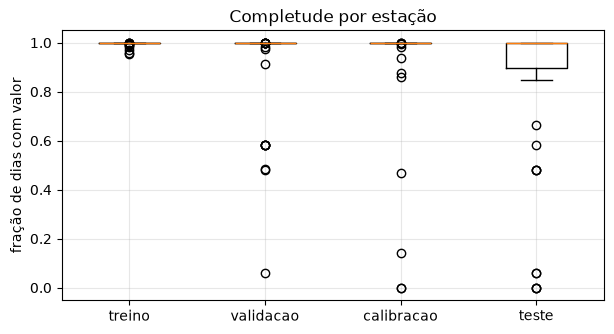

In [9]:
comp = serie.pivot_table(index="sensor_id", columns="split", values="observado", aggfunc="mean")[ORDEM]
display(comp.describe().T[["min", "25%", "50%", "75%", "max"]].round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([comp[s].dropna() for s in ORDEM])
ax.set_xticks(range(1, len(ORDEM) + 1)); ax.set_xticklabels(ORDEM)
ax.set(title="Completude por estação", ylabel="fração de dias com valor")
plt.show()

### 5.2 Lacunas (sequências de dias faltantes)
Lacunas longas são mais difíceis de reconstruir e derrubam janelas do GPLVM (descartadas com >50% de células invisíveis).

Comprimento das lacunas (dias): {'p50': 5.0, 'p90': 92.0, 'p99': 1151.9000000000021, 'p100': 2285.0}
Dias faltantes em lacunas de 7 dias ou mais: 98.5%


,count,median,max,sum
split,,,,
treino,81,2.0,150,571
validacao,23,13.0,2285,7063
calibracao,19,9.0,1188,1623
teste,88,92.0,823,7819


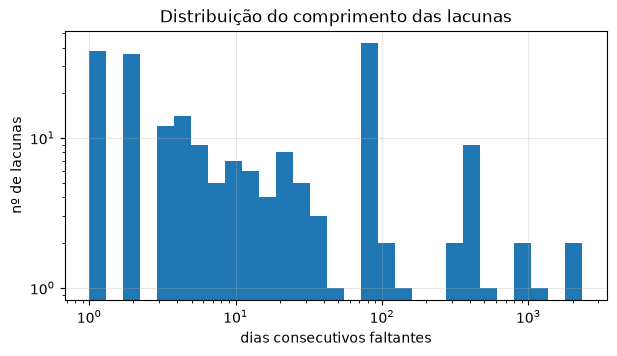

In [10]:
def comprimentos(m):
    # m: vetor booleano; devolve início e comprimento de cada sequência de True
    d = np.diff(np.r_[0, m.astype(int), 0])
    ini, fim = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    return ini, fim - ini

linhas = []
for sid, g in serie.sort_values("t").groupby("sensor_id"):
    ini, comp_run = comprimentos(g["observado"].to_numpy() == 0)
    spl = g["split"].to_numpy()
    linhas += [(sid, spl[i], c) for i, c in zip(ini, comp_run)]
lacunas = pd.DataFrame(linhas, columns=["sensor_id", "split", "comprimento"])

if lacunas.empty:
    print("Nenhuma lacuna na base.")
else:
    q = lacunas["comprimento"].quantile([0.5, 0.9, 0.99, 1.0]).rename(index=lambda x: f"p{int(x*100)}")
    print("Comprimento das lacunas (dias):", q.to_dict())
    pct7 = 100 * lacunas.loc[lacunas["comprimento"] >= 7, "comprimento"].sum() / lacunas["comprimento"].sum()
    print(f"Dias faltantes em lacunas de 7 dias ou mais: {pct7:.1f}%")
    display(lacunas.groupby("split")["comprimento"].agg(["count", "median", "max", "sum"]).reindex(ORDEM))

    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(lacunas["comprimento"], bins=np.logspace(0, np.log10(max(lacunas["comprimento"].max(), 2)) + 0.01, 30))
    ax.set(xscale="log", yscale="log", title="Distribuição do comprimento das lacunas",
           xlabel="dias consecutivos faltantes", ylabel="nº de lacunas")
    plt.show()

### 5.3 Zeros e negativos
Vazão zero indica rio intermitente: o `log1p` a trata bem, mas pode gerar pico de massa em um valor só.

In [11]:
obs = serie[serie["observado"] == 1]
zero_frac = (obs.assign(z=obs["y_bruto"].eq(0))
             .groupby(["sensor_id", "split"])["z"].mean().unstack()[ORDEM])
display((100 * zero_frac).describe().T[["min", "50%", "max"]].round(2).rename(columns={"50%": "mediana"}))
print("Valores negativos:", int((obs["y_bruto"] < 0).sum()))

,min,mediana,max
split,,,
treino,0.0,0.0,4.56
validacao,0.0,0.0,42.65
calibracao,0.0,0.0,83.05
teste,0.0,0.0,76.19


Valores negativos: 0


## 6. Rótulos de anomalia
A coluna `anomalia` vem dos qualificadores da USGS (`ICE`, `EQUIP`, `BACKWATER`, `MAINT`, `FLOOD`). Ela **só avalia**: nenhum modelo a vê. Como o gabarito é incompleto, a precisão será um limite inferior.

### 6.1 Volume por split

In [12]:
rot = serie.groupby("split", sort=False).agg(dias=("t", "size"), anomalias=("anomalia", "sum")).loc[ORDEM]
rot["taxa_%"] = (100 * rot["anomalias"] / rot["dias"]).round(2)
display(rot)

,dias,anomalias,taxa_%
split,,,
treino,701200,2951,0.42
validacao,175400,525,0.30
calibracao,116800,417,0.36
teste,175400,862,0.49


### 6.2 Concentração por estação e estabilidade ao longo do tempo

In [13]:
por_est = serie.pivot_table(index="sensor_id", columns="split", values="anomalia", aggfunc="sum")[ORDEM]
conc = pd.DataFrame({
    "estações com anomalia": (por_est > 0).sum(),
    "top 5 estações (% das anomalias)": [
        100 * por_est[s].nlargest(5).sum() / por_est[s].sum() if por_est[s].sum() else np.nan for s in ORDEM],
})
display(conc.round(1))

pos = por_est[["validacao", "calibracao", "teste"]].sum(axis=1)
some = por_est[(por_est["treino"] > 0) & (pos == 0)]
nasce = por_est[(por_est["treino"] == 0) & (pos > 0)]
print(f"Estações com anomalia no treino e nenhuma depois: {len(some)} de {N_EST}")
print(f"Estações sem anomalia no treino e com anomalia depois: {len(nasce)} de {N_EST}")

,estações com anomalia,top 5 estações (% das anomalias)
split,,
treino,69,32.0
validacao,27,77.5
calibracao,19,64.3
teste,33,49.3


Estações com anomalia no treino e nenhuma depois: 31 de 200
Estações sem anomalia no treino e com anomalia depois: 19 de 200


**Atenção:** estações cujos rótulos "somem" depois do treino (invernos marcados só como `ESTIMATED`) tendem a produzir falsos positivos aparentes. Isso é uma limitação do gabarito, não do modelo.

### 6.3 Quais qualificadores e qual status de aprovação

In [14]:
qual = (serie.loc[serie["qualificador"] != "", ["split", "qualificador"]]
        .assign(qualificador=lambda d: d["qualificador"].str.upper().str.split(";"))
        .explode("qualificador").reset_index(drop=True))
qual["qualificador"] = qual["qualificador"].str.strip()
tab = pd.crosstab(qual["qualificador"], qual["split"]).reindex(columns=ORDEM, fill_value=0)
tab["total"] = tab.sum(axis=1)
display(tab.sort_values("total", ascending=False).head(15))

apr = pd.crosst
ab(serie["split"], serie["aprovacao"].replace("", "(sem valor)"), normalize="index").loc[ORDEM]
display((100 * apr).round(1))

split,treino,validacao,calibracao,teste,total
qualificador,,,,,
ESTIMATED,71859,19188,17321,20539,128907
ICE,2172,451,215,693,3531
REVISED,1919,929,218,313,3379
EQUIP,594,72,201,148,1015
FORCEINTERPOLATION,129,80,143,196,548
RATINGDEV,0,0,0,293,293
BACKWATER,131,2,0,0,133
DIFFDATUM,115,0,0,0,115
FLOOD,54,0,0,20,74


AttributeError: module 'pandas' has no attribute 'crosst'

### 6.4 Quando as anomalias ocorrem

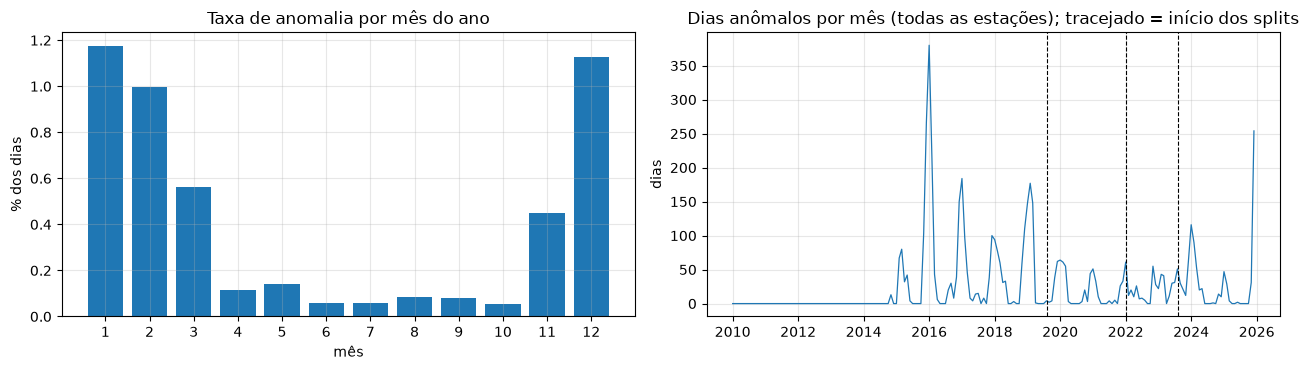

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
mes = serie.assign(mes=serie["data"].dt.month).groupby("mes")["anomalia"].mean() * 100
axs[0].bar(mes.index, mes.values)
axs[0].set(title="Taxa de anomalia por mês do ano", xlabel="mês", ylabel="% dos dias", xticks=range(1, 13))

mensal = serie.set_index("data")["anomalia"].resample("MS").sum()
axs[1].plot(mensal.index, mensal.values, lw=0.9)
for s in ORDEM[1:]:
    axs[1].axvline(serie.loc[serie["split"] == s, "data"].min(), color="k", ls="--", lw=0.8)
axs[1].set(title="Dias anômalos por mês (todas as estações); tracejado = início dos splits", ylabel="dias")
plt.tight_layout(); plt.show()

### 6.5 Anomalias regionais ou locais?
Se muitas estações são marcadas no mesmo dia, o evento é regional (ex.: onda de frio). Isso importa para a leitura dos modelos compartilhados (RGP‑t e GPLVM).

In [16]:
por_dia = serie.groupby("data")["anomalia"].sum()
dias_com = por_dia[por_dia > 0]
if dias_com.empty:
    print("Nenhum dia anômalo.")
else:
    frac_est = dias_com / N_EST
    print(f"Dias com alguma anomalia: {len(dias_com)}")
    print(f"  ... com 2+ estações marcadas: {100 * (dias_com >= 2).mean():.1f}%")
    print(f"  ... com 10%+ das estações marcadas (regional): {100 * (frac_est >= 0.10).mean():.1f}%")
    print(f"Mediana de estações marcadas por dia anômalo: {dias_com.median():.0f}")

Dias com alguma anomalia: 1853
  ... com 2+ estações marcadas: 51.5%
  ... com 10%+ das estações marcadas (regional): 0.0%
Mediana de estações marcadas por dia anômalo: 2


## 7. Distribuição e deriva
### 7.1 Assimetria: efeito do `log1p` e da padronização
Vazão é muito assimétrica; sem transformação, a cauda dominaria os modelos. Valores de assimetria próximos de 0 indicam distribuição mais simétrica.

In [17]:
vis = serie[serie["visivel"] == 1]
v_tr = vis[vis["split"] == "treino"]
g = v_tr.groupby("sensor_id")
assim = pd.DataFrame({
    "bruto": g["y_bruto"].skew(),
    "log1p": np.log1p(v_tr["y_bruto"]).groupby(v_tr["sensor_id"]).skew(),
    "y (final)": g["y"].skew(),
})
display(assim.describe().T[["min", "25%", "50%", "75%", "max"]].round(2))
print("Parâmetros de normalização por estação (escala log1p):")
display(stats.describe().T[["min", "50%", "max"]].round(3))

,min,25%,50%,75%,max
bruto,-5.59,2.49,3.59,6.99,44.45
log1p,-6.72,0.19,0.64,1.11,4.55
y (final),-6.72,0.19,0.64,1.11,4.55


Parâmetros de normalização por estação (escala log1p):


,min,50%,max
mean,0.458,4.594,10.479
std,0.115,1.037,2.252


### 7.2 Deriva entre splits
Se média ou desvio de `y` mudam do treino para o teste, o modelo estará extrapolando (clima, regulação, mudança de medição). Um valor próximo de 0 na média e de 1 no desvio, em todos os splits, indica estabilidade.

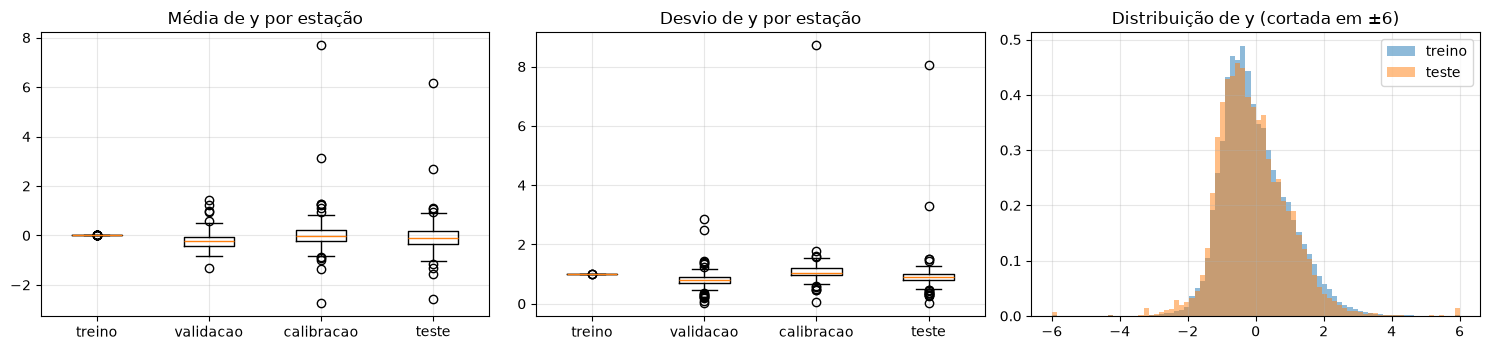

Valores extremos (|y| > 4.0) por split, em %:
{'treino': 0.201, 'validacao': 0.266, 'calibracao': 0.683, 'teste': 0.488}


In [18]:
media_s = vis.pivot_table(index="sensor_id", columns="split", values="y", aggfunc="mean")[ORDEM]
desv_s = vis.pivot_table(index="sensor_id", columns="split", values="y", aggfunc="std")[ORDEM]

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, df_, tit in ((axs[0], media_s, "Média de y por estação"), (axs[1], desv_s, "Desvio de y por estação")):
    ax.boxplot([df_[s].dropna() for s in ORDEM]); ax.set_xticks(range(1, 5)); ax.set_xticklabels(ORDEM); ax.set_title(tit)
for s in ("treino", "teste"):
    axs[2].hist(vis.loc[vis["split"] == s, "y"].clip(-6, 6), bins=80, density=True, alpha=0.5, label=s)
axs[2].set(title="Distribuição de y (cortada em ±6)"); axs[2].legend()
plt.tight_layout(); plt.show()

ext = vis.assign(e=vis["y"].abs() > LIM_EXTREMO).groupby("split")["e"].mean().loc[ORDEM] * 100
print(f"Valores extremos (|y| > {LIM_EXTREMO}) por split, em %:")
print(ext.round(3).to_dict())

Extremos sem qualificador costumam ser **cheias reais**, não erros: escores altos nesses dias não são falha do modelo.

## 8. Estrutura temporal
### 8.1 Autocorrelação (ACF)
Correlação da série com ela mesma deslocada em *k* dias, calculada no treino visível, ignorando faltantes. Valores altos em 1 e 7 indicam memória curta; alto em 365 indica sazonalidade anual.

In [19]:
y_wide = serie.pivot(index="t", columns="sensor_id", values="y")
v_wide = serie.pivot(index="t", columns="sensor_id", values="visivel")
y_vis = y_wide.where(v_wide == 1)
split_t = serie.drop_duplicates("t").set_index("t").sort_index()["split"]
W_tr = y_vis.loc[split_t[split_t == "treino"].index]

acf = pd.DataFrame({f"lag {k}": [W_tr[c].autocorr(k) for c in W_tr.columns] for k in LAGS}, index=W_tr.columns)
display(acf.describe().T[["min", "25%", "50%", "75%", "max"]].round(3))

,min,25%,50%,75%,max
lag 1,0.581,0.969,0.985,0.993,0.998
lag 7,0.240,0.821,0.889,0.924,0.977
lag 30,0.023,0.543,0.640,0.724,0.870
lag 182,-0.767,-0.316,-0.127,0.031,0.392
lag 365,-0.077,0.353,0.486,0.609,0.920


### 8.2 Periodograma
Mostra em quais períodos (dias) está a energia da série. O pico dá o período sazonal que o kernel periódico do GP e a janela do GPLVM devem respeitar.

*Só para este diagnóstico*, os faltantes do treino são interpolados linearmente a série é multiplicada por uma janela de Hann e a FFT usa zero-padding (grade de períodos mais fina). Nada disso volta para a base.

Período dominante (dias): mediana 364 | p10 356 | p90 372
Estações com pico entre 330 e 400 dias: 86%
Parcela da energia na faixa anual (330-400 dias), mediana: 39%


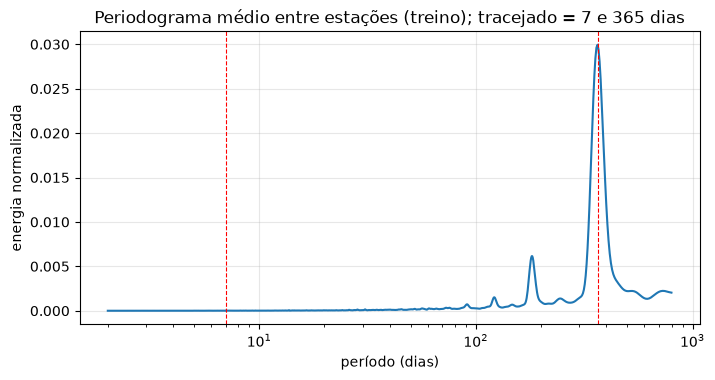

In [20]:
NFFT = 2 ** 15

def periodograma(y):
    s = pd.Series(y).interpolate(limit_direction="both").to_numpy()
    s = s - s.mean()
    p = np.abs(np.fft.rfft(s * np.hanning(len(s)), n=NFFT)) ** 2   # zero-padding: grade de períodos mais fina
    f = np.fft.rfftfreq(NFFT, d=1.0)
    return 1 / f[1:], p[1:]

pot, dominante, forca_anual = [], {}, {}
for c in W_tr.columns:
    if W_tr[c].notna().sum() < 100:
        continue
    per, p = periodograma(W_tr[c].to_numpy())
    m = (per >= PERIODO_MIN) & (per <= PERIODO_MAX)
    per_m, p_m = per[m], p[m]
    pot.append(p_m / p_m.sum())
    dominante[c] = per_m[np.argmax(p_m)]
    forca_anual[c] = p_m[(per_m >= 330) & (per_m <= 400)].sum() / p_m.sum()

dominante = pd.Series(dominante); forca_anual = pd.Series(forca_anual)
print(f"Período dominante (dias): mediana {dominante.median():.0f} | p10 {dominante.quantile(.1):.0f} | p90 {dominante.quantile(.9):.0f}")
print(f"Estações com pico entre 330 e 400 dias: {100 * dominante.between(330, 400).mean():.0f}%")
print(f"Parcela da energia na faixa anual (330-400 dias), mediana: {100 * forca_anual.median():.0f}%")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(per_m, np.mean(pot, axis=0))
for x in (7, 365):
    ax.axvline(x, color="r", ls="--", lw=0.8)
ax.set(xscale="log", title="Periodograma médio entre estações (treino); tracejado = 7 e 365 dias",
       xlabel="período (dias)", ylabel="energia normalizada")
plt.show()

### 8.3 Referência de sazonalidade: climatologia mensal
Previsão = média do mesmo mês no treino. **Não é o baseline oficial do projeto**; serve para dimensionar quanto da variância é sazonal. O R² é calculado nos pontos escondidos do teste.

In [21]:
d = serie.assign(mes=serie["data"].dt.month)
clim = (d[(d["split"] == "treino") & (d["visivel"] == 1)]
        .groupby(["sensor_id", "mes"])["y"].mean().rename("clim"))
alvo = d[(d["split"] == "teste") & (d["escondido_aval"] == 1)].join(clim, on=["sensor_id", "mes"])

r2_clim, rmse_clim = np.nan, np.nan
if alvo.empty:
    print("Sem pontos escondidos no teste.")
else:
    err2 = (alvo["y"] - alvo["clim"]) ** 2
    por_s = pd.DataFrame({
        "rmse": np.sqrt(err2.groupby(alvo["sensor_id"]).mean()),
        "r2": 1 - err2.groupby(alvo["sensor_id"]).mean() / alvo.groupby("sensor_id")["y"].var(),
    })
    rmse_clim, r2_clim = por_s["rmse"].median(), por_s["r2"].median()
    display(por_s.describe().T[["min", "25%", "50%", "75%", "max"]].round(3))
    print(f"Mediana: RMSE {rmse_clim:.3f} (escala y) | R² {r2_clim:.3f}")

,min,25%,50%,75%,max
rmse,0.292,0.541,0.695,0.886,9.447
r2,-79.993,-0.050,0.299,0.595,0.895


Mediana: RMSE 0.695 (escala y) | R² 0.299


Se o R² da climatologia já é alto, o ganho possível dos modelos está nos desvios em torno do ciclo sazonal. Se for baixo, a dinâmica de curto prazo pesa mais.

## 9. Dependência entre estações
Correlação de `y` entre pares de estações no treino. Correlação alta sustenta o compartilhamento de parâmetros (RGP‑t, GPLVM) e o GP multitarefa; correlação baixa favorece um GP por estação.

Correlação entre pares de estações (treino): {'p10': -0.048, 'mediana': 0.276, 'p90': 0.674}
Pares com correlação > 0.5: 22.9%


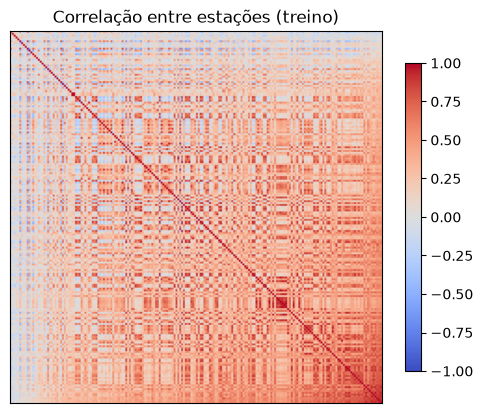

In [22]:
corr = W_tr.corr(min_periods=200)
off = corr.to_numpy()[np.triu_indices_from(corr.to_numpy(), k=1)]
off = off[~np.isnan(off)]
print("Correlação entre pares de estações (treino):",
      {k: round(float(np.quantile(off, q)), 3) for k, q in (("p10", .1), ("mediana", .5), ("p90", .9))})
print(f"Pares com correlação > 0.5: {100 * (off > 0.5).mean():.1f}%")

ordem_c = corr.mean().sort_values().index
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.loc[ordem_c, ordem_c].to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set(title="Correlação entre estações (treino)", xticks=[], yticks=[]); ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()

## 10. Janelas para o GPLVM
`gplvm_inputs` cria janelas sem sobreposição dentro de cada split, descarta as com mais de 50% de células invisíveis e o resto no fim de cada bloco. Os dias fora de janela ficam **sem escore** (NaN) e não entram nas métricas de detecção do Modelo 3. A tabela mostra o custo disso para cada tamanho de janela.

In [23]:
dias_split = serie.groupby("split").size()
anom_split = serie.groupby("split")["anomalia"].sum()
base = serie[["sensor_id", "t", "split", "anomalia"]]

linhas = []
for w in JANELAS:
    inp = gplvm_inputs(serie, window=w)
    meta = inp["meta"]
    dias = windows_to_days(inp, np.arange(len(meta)), "janela").merge(base, on=["sensor_id", "t"], how="left")
    por_jan = dias.groupby("janela").agg(split=("split", "first"), anom=("anomalia", "max"))
    for s in ORDEM:
        d_s = dias[dias["split"] == s]
        sel = meta["split"].eq(s).to_numpy()
        linhas.append({
            "janela": w, "split": s, "janelas": int(sel.sum()),
            "com anomalia": int(por_jan.loc[por_jan["split"] == s, "anom"].sum()),
            "cobertura de dias %": 100 * len(d_s) / dias_split[s],
            "cobertura de anomalias %": 100 * d_s["anomalia"].sum() / max(anom_split[s], 1),
            "células visíveis %": 100 * float(inp["mask"][sel].mean()) if sel.any() else np.nan,
        })
jan = pd.DataFrame(linhas).set_index(["janela", "split"])
display(jan.round(1))

janelas  com anomalia  cobertura de dias %  cobertura de anomalias %  células visíveis %
janela split                                                                                               
7      treino        99928           597                 99.8                     100.0               100.0
       validacao     24409           103                 97.4                      98.5                90.2
       calibracao    16250            94                 97.4                      99.3                90.2
       teste         23442           136                 93.6                      66.6                90.2
14     treino        49972           380                 99.8                     100.0               100.0
       validacao     12140            69                 96.9                      97.1                90.1
       calibracao     8049            63                 96.5                      97.6                90.0
       teste         11680            93                 93.2                      68.0                90.1
30     treino        23189           262                 99.2                     100.0               100.0
       validacao      5679            45                 97.1                      97.1                90.1
       calibracao     3731            45                 95.8                      96.6                90.0
       teste          5454            56                 93.3                      69.5                90.1

**Como ler:** `cobertura de anomalias %` baixa significa que muitas anomalias caem em janelas descartadas e o recall do Modelo 3 fica otimista frente aos modelos 1 e 2. Na comparação final, calcule as métricas só nos dias em que os três modelos têm saída.

## 11. Poder da avaliação no teste
Poucas anomalias, ou anomalias em poucas estações, tornam as métricas de detecção instáveis. Anomalias em dias seguidos formam **um episódio**; a resolução do recall abaixo usa episódios (estimativa mais conservadora que usar dias).

In [24]:
def n_episodios(a):
    a = np.asarray(a)
    return int(((a[1:] == 1) & (a[:-1] == 0)).sum() + (a[0] == 1))

epis = (serie.sort_values(["sensor_id", "t"]).groupby(["sensor_id", "split"])["anomalia"]
        .apply(lambda a: n_episodios(a.to_numpy())).groupby("split").sum())

pod = pd.DataFrame({
    "anomalias (dias)": serie.groupby("split")["anomalia"].sum(),
    "episódios": epis,
    "estações com anomalia": (por_est > 0).sum(),
    "pontos escondidos": serie.groupby("split")["escondido_aval"].sum(),
}).loc[ORDEM]
pod["resolução do recall (±)"] = 1.96 * np.sqrt(0.25 / pod["episódios"].clip(lower=1))
display(pod.round(3))

t = pod.loc["teste"]
if t["anomalias (dias)"] < MIN_ANOM_TESTE or t["estações com anomalia"] < MIN_EST_ANOM_TESTE:
    print(f"ATENÇÃO: teste com {int(t['anomalias (dias)'])} dias anômalos em {int(t['estações com anomalia'])} estações "
          f"(mínimo desejável: {MIN_ANOM_TESTE} dias e {MIN_EST_ANOM_TESTE} estações). "
          "Aumente n_sensors; não escolha estações olhando os rótulos do teste.")
else:
    print("Teste com volume de anomalias adequado aos critérios definidos.")

,anomalias (dias),episódios,estações com anomalia,pontos escondidos,resolução do recall (±)
split,,,,,
treino,2951,240,69,0,0.063
validacao,525,35,27,16993,0.166
calibracao,417,49,19,11342,0.140
teste,862,92,33,16305,0.102


Teste com volume de anomalias adequado aos critérios definidos.


## 12. Resumo e decisões

In [25]:
periodo_rec = int(round(dominante.median())) if len(dominante) else np.nan
resumo = pd.Series({
    "Estações": N_EST,
    "Dias por estação": N_DIAS,
    "Completude mediana no treino (%)": round(100 * comp["treino"].median(), 1),
    "Dias faltantes em lacunas ≥ 7 dias (%)": round(pct7, 1) if not lacunas.empty else 0.0,
    "Assimetria mediana: bruto → y": f"{assim['bruto'].median():.2f} → {assim['y (final)'].median():.2f}",
    "Período dominante mediano (dias)": periodo_rec,
    "ACF mediana lag 7 / lag 365": f"{acf['lag 7'].median():.2f} / {acf['lag 365'].median():.2f}",
    "R² da climatologia mensal (teste, mediana)": round(r2_clim, 3) if np.isfinite(r2_clim) else "n/d",
    "Correlação mediana entre estações": round(float(np.median(off)), 3) if len(off) else "n/d",
    "Anomalias no teste (dias / episódios)": f"{int(t['anomalias (dias)'])} / {int(t['episódios'])}",
    "Estações com anomalia no teste": int(t["estações com anomalia"]),
    "Cobertura de anomalias no teste, janela 7 (%)": round(float(jan.loc[(7, "teste"), "cobertura de anomalias %"]), 1) if 7 in JANELAS else "n/d",
})
display(resumo.to_frame("valor"))

,valor
Estações,200
Dias por estação,5844
Completude mediana no treino (%),100.0
Dias faltantes em lacunas ≥ 7 dias (%),98.5
Assimetria mediana: bruto → y,3.59 → 0.64
Período dominante mediano (dias),364
ACF mediana lag 7 / lag 365,0.89 / 0.49
"R² da climatologia mensal (teste, mediana)",0.299
Correlação mediana entre estações,0.276
Anomalias no teste (dias / episódios),862 / 92


In [28]:
import numpy as np  # Calcula logaritmos, estatísticas e funções circulares.
import pandas as pd  # Organiza e resume as séries em tabelas.
from src.download import load_selected  # Carrega o catálogo local de estações selecionadas.
from src.main import default_download_config  # Obtém a configuração local usada para localizar a seleção.
cfg = default_download_config()  # Cria a configuração padrão do projeto, sem fazer chamadas à API.
estacoes = load_selected(cfg)  # Lê do disco a lista de estações usada na base.
if "state_name" not in estacoes.columns:  # Verifica se a seleção contém o estado de cada estação.
    raise ValueError("A seleção precisa conter a coluna 'state_name'.")  # Interrompe com uma explicação se a coluna faltar.
mapa_estados = estacoes[["monitoring_location_id", "state_name"]].drop_duplicates()  # Mantém o vínculo entre estação e estado.
if mapa_estados["monitoring_location_id"].duplicated().any():  # Verifica se um ID está associado a mais de um estado.
    raise ValueError("Há estações associadas a mais de um estado na seleção.")  # Interrompe se o catálogo tiver associação ambígua.
dados_treino = serie.loc[  # Seleciona a parte da base adequada para análise sem usar validação ou teste.
    (serie["split"] == "treino") & (serie["visivel"] == 1)  # Mantém somente observações visíveis do bloco de treino.
].copy()  # Copia a seleção para criar colunas sem alterar a tabela original.
if dados_treino.empty:  # Verifica se restaram dados para calcular as assinaturas.
    raise ValueError("Não há pontos visíveis no treino para calcular as assinaturas.")  # Explica por que a análise não pode continuar.
dados_treino["sensor_id"] = dados_treino["sensor_id"].astype(str)  # Padroniza o ID para combinar com o catálogo.
dados_treino = dados_treino.merge(  # Acrescenta o estado associado a cada estação.
    mapa_estados,  # Usa a tabela de estados obtida do catálogo local.
    left_on="sensor_id",  # Indica o nome da coluna de estação na base de modelagem.
    right_on="monitoring_location_id",  # Indica o nome correspondente da coluna no catálogo.
    how="left",  # Mantém as linhas da base de modelagem.
    validate="many_to_one",  # Exige que cada estação tenha no máximo um estado.
)  # Finaliza a junção entre os dados temporais e os estados.
if dados_treino["state_name"].isna().any():  # Verifica se todas as estações receberam um estado.
    raise ValueError("Não foi possível associar o estado a todas as estações de treino.")  # Interrompe se houver IDs sem correspondência.
forca_anual_por_estacao = pd.Series(  # Converte a força anual já calculada na seção do periodograma em uma série indexada.
    globals().get("forca_anual", pd.Series(dtype=float)), dtype=float  # Usa a variável anterior; se ela não existir, deixa o valor ausente.
)  # Finaliza a conversão para uma estrutura consultável por estação.
forca_anual_por_estacao.index = forca_anual_por_estacao.index.astype(str)  # Padroniza os IDs do índice para o mesmo tipo do sensor_id.
linhas_assinaturas = []  # Guarda uma linha de métricas para cada estação.
for sensor_id, grupo in dados_treino.groupby("sensor_id", sort=True):  # Calcula as métricas separadamente para cada estação.
    grupo = grupo.sort_values("data").copy()  # Ordena a estação cronologicamente antes das operações temporais.
    grupo["data"] = pd.to_datetime(grupo["data"])  # Garante que as datas estejam no formato datetime.
    vazao = grupo.set_index("data")["y_bruto"].astype(float).asfreq("D")  # Cria uma série diária em vazão bruta e mantém lacunas como NaN.
    observada = vazao.dropna()  # Separa os dias com vazão observada para as estatísticas.
    if observada.empty:  # Verifica se a estação tem pelo menos uma medida válida.
        continue  # Ignora esta estação se não houver vazões observadas.
    media_vazao = observada.mean()  # Calcula a vazão média observada no treino.
    media_log_vazao = np.log1p(observada).mean()  # Calcula a média de log1p da vazão para reduzir o efeito de picos extremos.
    media_movel_7d = vazao.rolling(window=7, min_periods=7).mean().dropna()  # Calcula médias móveis apenas em janelas com sete dias observados.
    proxy_minima_7d = media_movel_7d.min() / media_vazao if len(media_movel_7d) and media_vazao > 0 else np.nan  # Calcula a proxy de vazão baixa pedida, sem chamá-la de BFI canônico.
    proxy_p10_7d = media_movel_7d.quantile(0.10) / media_vazao if len(media_movel_7d) and media_vazao > 0 else np.nan  # Calcula uma proxy de baixa vazão menos sensível a um único mínimo.
    dias_consecutivos = vazao.notna() & vazao.shift(1).notna()  # Marca somente os pares de dias consecutivos com as duas vazões observadas.
    fracao_pares_consecutivos = dias_consecutivos.sum() / max(observada.size - 1, 1)  # Mede quanto dos pares possíveis de dias observados é consecutivo.
    denominador_rbi = observada.sum()  # Soma as vazões observadas para normalizar o índice de Richards–Baker.
    rbi = vazao.diff().abs().where(dias_consecutivos).sum() / denominador_rbi if denominador_rbi > 0 else np.nan  # Calcula a flashiness usando apenas diferenças diárias válidas.
    if fracao_pares_consecutivos < 0.80:  # Evita confiar em um RBI calculado com poucas transições diárias observadas.
        rbi = np.nan  # Marca o índice como ausente quando a cobertura consecutiva é insuficiente.
    lag1 = vazao.corr(vazao.shift(1)) if fracao_pares_consecutivos >= 0.80 else np.nan  # Calcula autocorrelação diária somente se houver cobertura consecutiva adequada.
    fracao_zeros = observada.eq(0).mean()  # Calcula a fração de vazões observadas que são zero.
    picos_anuais = observada.groupby(observada.index.year).idxmax()  # Encontra a data da vazão máxima observada em cada ano.
    angulos_pico = np.array([  # Converte cada pico anual para um ângulo do ciclo sazonal.
        2 * np.pi * (data_pico.dayofyear - 1) / (366 if data_pico.is_leap_year else 365)  # Ajusta o ciclo à duração do ano.
        for data_pico in pd.DatetimeIndex(picos_anuais.to_numpy())  # Percorre as datas dos picos anuais.
    ])  # Finaliza a lista de ângulos de pico.
    seno_pico = np.sin(angulos_pico).mean() if len(angulos_pico) else np.nan  # Calcula a componente seno média da época do pico.
    cosseno_pico = np.cos(angulos_pico).mean() if len(angulos_pico) else np.nan  # Calcula a componente cosseno média da época do pico.
    dia_pico_circular = (np.arctan2(seno_pico, cosseno_pico) % (2 * np.pi)) * 365.2425 / (2 * np.pi) + 1 if len(angulos_pico) else np.nan  # Resume a época média do pico de forma circular.
    concentracao_picos = np.hypot(seno_pico, cosseno_pico) if len(angulos_pico) else np.nan  # Mede a consistência da época dos picos entre anos, de zero a um.
    linhas_assinaturas.append({  # Guarda as métricas desta estação.
        "sensor_id": sensor_id,  # Identificador da estação.
        "state_name": grupo["state_name"].iloc[0],  # Estado da estação.
        "dias_observados_treino": int(observada.size),  # Número de dias observados usados nas métricas.
        "cobertura_pares_consecutivos": fracao_pares_consecutivos,  # Fração de transições diárias que pôde ser avaliada.
        "log1p_vazao_media": media_log_vazao,  # Assinatura de magnitude em escala logarítmica.
        "proxy_minima_media_movel_7d": proxy_minima_7d,  # Proxy de baixa vazão baseada no menor valor da média móvel.
        "proxy_p10_media_movel_7d": proxy_p10_7d,  # Proxy de baixa vazão baseada no percentil dez da média móvel.
        "indice_richards_baker": rbi,  # Assinatura de oscilação diária.
        "fracao_zeros": fracao_zeros,  # Assinatura de constância baseada em dias sem vazão.
        "autocorrelacao_lag_1": lag1,  # Assinatura de persistência entre dias consecutivos.
        "dia_pico_circular": dia_pico_circular,  # Época média do pico anual, em dia aproximado do ano.
        "concentracao_epoca_picos": concentracao_picos,  # Consistência da época de pico entre anos.
        "forca_anual_periodograma": forca_anual_por_estacao.get(sensor_id, np.nan),  # Reaproveita a força anual calculada anteriormente no notebook.
    })  # Finaliza o registro da estação.
assinaturas = pd.DataFrame(linhas_assinaturas).set_index(["state_name", "sensor_id"]).sort_index()  # Organiza as assinaturas por estado e estação.
display(assinaturas.round(3))  # Exibe as assinaturas arredondadas para facilitar a leitura.

dias_observados_treino  cobertura_pares_consecutivos  log1p_vazao_media  proxy_minima_media_movel_7d  \
state_name sensor_id                                                                                                             
California USGS-09429170                    3506                           1.0              1.993                        0.000   
           USGS-09429190                    3506                           1.0              1.889                        0.000   
           USGS-09429490                    3506                           1.0              8.890                        0.386   
           USGS-10254730                    3506                           1.0              6.658                        0.441   
           USGS-10254970                    3506                           1.0              4.572                        0.424   
...                                          ...                           ...                ...                          ...   
Montana    USGS-12365700                    3506                           1.0              5.378                        0.114   
           USGS-12375900                    3506                           1.0              2.786                        0.197   
           USGS-12381400                    3506                           1.0              3.632                        0.037   
           USGS-12388700                    3506                           1.0              9.275                        0.279   
           USGS-12390700                    3506                           1.0              4.862                        0.124   

                          proxy_p10_media_movel_7d  indice_richards_baker  fracao_zeros  autocorrelacao_lag_1  dia_pico_circular  \
state_name sensor_id                                                                                                               
California USGS-09429170                     0.498                  0.513         0.037                 0.418            347.980   
           USGS-09429190                     0.383                  0.352         0.041                 0.818            327.747   
           USGS-09429490                     0.655                  0.070         0.000                 0.944            100.207   
           USGS-10254730                     0.746                  0.049         0.000                 0.929            207.276   
           USGS-10254970                     0.633                  0.068         0.000                 0.873             23.742   
...                                            ...                    ...           ...                   ...                ...   
Montana    USGS-12365700                     0.207                  0.046         0.000                 0.997            133.241   
           USGS-12375900                     0.287                  0.095         0.000                 0.973            164.229   
           USGS-12381400                     0.158                  0.074         0.000                 0.991            145.729   
           USGS-12388700                     0.420                  0.029         0.000                 0.997            160.208   
           USGS-12390700                     0.186                  0.090         0.000                 0.970            122.370   

                          concentracao_epoca_picos  forca_anual_periodograma  
state_name sensor_id                                                          
California USGS-09429170                     0.452                     0.025  
           USGS-09429190                     0.103                     0.037  
           USGS-09429490                     0.861                     0.505  
           USGS-10254730                     0.349                     0.179  
           USGS-10254970                     0.340                     0.516  
...                                            ...               

A razão entre a menor média móvel de 7 dias e a vazão média é uma proxy de vazão baixa, não o índice de vazão de base (Baseflow Index) canônico. Esse índice normalmente envolve separar o escoamento de base do escoamento total. Incluí também o percentil 10 da média móvel, que é menos sensível a um único período de seca.
O índice Richards–Baker é calculado usando apenas pares de dias consecutivos observados. Não contamos a diferença entre observações separadas por lacunas como se fossem dias seguidos.

## 13. Análise hidrológica das 200 estações, antes dos splits

Esta seção usa `serie` **somente para obter os IDs das 200 estações escolhidas**. Em seguida, carrega os Parquets diários originais dessas estações pelos módulos existentes. As assinaturas e os gráficos usam o período completo disponível, antes de treino/validação/calibração/teste, sem normalizar nem imputar vazões. Os dias sem medição permanecem como lacunas.

A seleção de 200 estações não é estratificada por estado. A primeira célula mostra a contagem real; os três estados do catálogo recebem uma figura cada, e um estado sem estação na amostra será identificado explicitamente. Como estas análises usam o período completo, são descritivas: não use os seus resultados para escolher hiperparâmetros avaliados no teste.

In [ ]:
from src.download import load_daily, load_selected  # Reutiliza a leitura dos Parquets e do catálogo local.
from src.main import default_download_config  # Reutiliza as datas e os caminhos configurados no projeto.
from src.processing import complete_daily_calendar, make_station_observation_table  # Reutiliza os preparadores diários existentes.
cfg_hidro = default_download_config()  # Obtém a configuração sem consultar a API.
ids_200 = set(serie["sensor_id"].astype(str).unique())  # Usa serie somente como fonte dos IDs selecionados para os modelos.
if len(ids_200) != 200:  # Confirma que a base atual contém as 200 estações esperadas.
    raise ValueError(f"Esperava 200 estações em serie, mas encontrei {len(ids_200)}.")  # Interrompe se a amostra usada não for a esperada.
catalogo = load_selected(cfg_hidro)  # Lê a seleção do download salva pelo pipeline.
catalogo["monitoring_location_id"] = catalogo["monitoring_location_id"].astype(str)  # Padroniza os IDs para a junção.
if "state_name" not in catalogo.columns:  # Confirma que o catálogo identifica o estado de cada estação.
    raise ValueError("O catálogo não contém a coluna state_name.")  # Explica a ausência necessária para separar os gráficos por estado.
estacoes_200 = catalogo.loc[catalogo["monitoring_location_id"].isin(ids_200)].copy()  # Restringe o catálogo às estações de serie.
if estacoes_200["monitoring_location_id"].duplicated().any():  # Confirma que há uma única série selecionada por estação.
    raise ValueError("Há IDs de estação duplicados no catálogo selecionado.")  # Evita atribuições ambíguas de série ou estado.
if set(estacoes_200["monitoring_location_id"]) != ids_200:  # Confirma que o catálogo contém todos os IDs de serie.
    raise ValueError("Nem todas as estações de serie foram encontradas no catálogo do download.")  # Evita analisar uma amostra incompleta.
contagem_estado_200 = estacoes_200.groupby("state_name")["monitoring_location_id"].nunique().sort_values(ascending=False)  # Conta as estações por estado sem reamostrar.
print("Distribuição real das 200 estações; a seleção não é estratificada:")  # Explica a interpretação da contagem.
display(contagem_estado_200)  # Exibe o número selecionado em cada estado.
ids_ts_200 = estacoes_200["time_series_id"].dropna().astype(str).tolist()  # Obtém os IDs das séries USGS correspondentes às estações.
observacoes_200 = load_daily(cfg_hidro, ids_ts_200)  # Carrega somente os Parquets das estações de serie.
ids_ts_carregados = set(observacoes_200["time_series_id"].astype(str).unique())  # Identifica as séries com arquivo de observações local.
if set(ids_ts_200) - ids_ts_carregados:  # Verifica se há arquivos de séries ausentes.
    raise FileNotFoundError("Faltam Parquets de uma ou mais séries das 200 estações selecionadas.")  # Não permite resultados incompletos sem aviso.
observacoes_200 = make_station_observation_table(observacoes_200, estacoes_200)  # Usa a função do projeto para associar vazões e estações.
observacoes_200["monitoring_location_id"] = observacoes_200["monitoring_location_id"].astype(str)  # Padroniza a chave da estação.
dados_hidro = complete_daily_calendar(observacoes_200, start=cfg_hidro.date_start, end=cfg_hidro.date_end)  # Expande ao calendário completo sem imputar vazões.
dados_hidro["monitoring_location_id"] = dados_hidro["monitoring_location_id"].astype(str)  # Mantém a chave como texto após completar o calendário.
dados_hidro = dados_hidro.merge(estacoes_200[["monitoring_location_id", "state_name"]], on="monitoring_location_id", how="left", validate="many_to_one")  # Junta o estado sem alterar os dados medidos.
if dados_hidro["state_name"].isna().any():  # Confirma que todas as linhas foram associadas a um estado.
    raise ValueError("Há dados diários sem estado associado.")  # Interrompe se a classificação geográfica estiver incompleta.
print(f"Base hidrológica bruta: {dados_hidro['monitoring_location_id'].nunique()} estações, {dados_hidro['date'].min():%Y-%m-%d} a {dados_hidro['date'].max():%Y-%m-%d}.")  # Resume a base analisada antes dos splits.

### 13.1 Assinaturas por estação

As métricas são descritores operacionais do projeto, não todas índices hidrológicos canônicos. `Q90` abaixo significa vazão excedida em 90% do tempo (percentil 10 dos valores); a razão com a média facilita comparar estações de magnitudes diferentes. O percentil 10 da média móvel de sete dias é uma proxy de baixa vazão, não o *Baseflow Index*. Richards–Baker e autocorrelação no lag 1 só são reportados quando há cobertura suficiente de pares diários consecutivos. A força anual do periodograma usa o maior trecho contínuo, interpolando apenas lacunas internas de até sete dias.

In [ ]:
from scipy.signal import periodogram  # Calcula a potência espectral das séries diárias.
series_hidro = {}  # Guarda cada série bruta completa para os gráficos.
picos_anuais_hidro = {}  # Guarda datas dos picos anuais aceitos pelo critério de cobertura.
linhas_assinaturas_hidro = []  # Guarda as assinaturas calculadas para cada estação.
def calcular_forca_anual(vazao):  # Calcula a proporção de energia espectral em períodos anuais.
    preenchida = vazao.interpolate(method="time", limit=7, limit_area="inside")  # Interpola somente lacunas internas de até sete dias para este diagnóstico.
    mascara = preenchida.notna().to_numpy()  # Marca os dias disponíveis após a interpolação limitada.
    mudancas = np.diff(np.r_[False, mascara, False].astype(int))  # Localiza os limites dos trechos temporais contínuos.
    inicios = np.flatnonzero(mudancas == 1)  # Obtém o início de cada trecho válido.
    finais = np.flatnonzero(mudancas == -1)  # Obtém o fim exclusivo de cada trecho válido.
    if len(inicios) == 0:  # Verifica se algum trecho temporal pode ser analisado.
        return np.nan  # Retorna ausente quando não há trecho contínuo.
    maior = int(np.argmax(finais - inicios))  # Seleciona o trecho contínuo mais longo.
    trecho = preenchida.iloc[inicios[maior]:finais[maior]].to_numpy(dtype=float)  # Extrai o trecho como valores numéricos.
    if len(trecho) < 3 * 365:  # Exige pelo menos três anos para estimar sazonalidade anual.
        return np.nan  # Evita uma estimativa anual instável com pouco histórico.
    frequencias, potencia = periodogram(trecho, fs=1.0, window="hann", detrend="linear", scaling="spectrum")  # Calcula o espectro com tendência linear removida.
    validas = frequencias > 0  # Exclui a frequência zero do espectro.
    periodos = 1 / frequencias[validas]  # Converte frequência diária em período medido em dias.
    potencia = potencia[validas]  # Mantém as potências correspondentes às frequências válidas.
    faixa = (periodos >= 2) & (periodos <= 800)  # Limita a análise a períodos entre dois e oitocentos dias.
    anual = faixa & (periodos >= 330) & (periodos <= 400)  # Define a faixa próxima de um ciclo anual.
    total = potencia[faixa].sum()  # Soma a energia total na faixa de períodos analisada.
    return potencia[anual].sum() / total if total > 0 else np.nan  # Devolve a fração da energia na faixa anual.
for (estado, sensor_id), grupo in dados_hidro.groupby(["state_name", "monitoring_location_id"], sort=True):  # Analisa cada estação e estado separadamente.
    vazao = grupo.set_index("date")["value_cfs"].astype(float).sort_index()  # Recupera a série diária original em ft³/s.
    observada = vazao.dropna()  # Seleciona dias medidos sem preencher valores ausentes.
    if observada.empty:  # Verifica se a estação possui ao menos uma medição.
        continue  # Ignora apenas estações sem qualquer vazão observada.
    media = observada.mean()  # Calcula a vazão média bruta no período completo.
    media_7d = vazao.rolling(7, min_periods=7).mean().dropna()  # Calcula médias móveis em janelas de sete dias integralmente observadas.
    pares = vazao.notna() & vazao.shift(1).notna()  # Marca pares válidos de dias adjacentes.
    cobertura_pares = pares.sum() / max(len(vazao) - 1, 1)  # Calcula a fração de transições diárias observadas.
    denominador_rbi = vazao[pares].sum()  # Soma as vazões finais dos pares incluídos no cálculo do índice.
    rbi = vazao.diff().abs().where(pares).sum() / denominador_rbi if denominador_rbi > 0 else np.nan  # Calcula Richards–Baker sem cruzar lacunas.
    acf1 = vazao.corr(vazao.shift(1)) if cobertura_pares >= 0.80 else np.nan  # Calcula autocorrelação diária somente com cobertura de pares adequada.
    rbi = rbi if cobertura_pares >= 0.80 else np.nan  # Oculta RBI quando há menos de 80% de cobertura das transições.
    picos_ano = []  # Armazena um pico anual para cada ano suficientemente observado.
    for ano, valores_ano in vazao.groupby(vazao.index.year):  # Percorre os anos da série diária completa.
        if valores_ano.notna().mean() >= 0.80 and valores_ano.notna().any():  # Exige cobertura anual de pelo menos 80%.
            picos_ano.append(valores_ano.idxmax())  # Guarda a data da maior vazão observada no ano.
    picos_anuais_hidro[str(sensor_id)] = pd.DatetimeIndex(picos_ano)  # Salva os picos para os gráficos.
    if picos_ano:  # Confere se há picos anuais para resumir a época do ano.
        angulos = np.array([2 * np.pi * (data.dayofyear - 1) / (366 if data.is_leap_year else 365) for data in picos_ano])  # Converte datas em ângulos anuais.
        seno = np.sin(angulos).mean()  # Calcula a componente seno média da época dos picos.
        cosseno = np.cos(angulos).mean()  # Calcula a componente cosseno média da época dos picos.
        dia_pico = (np.arctan2(seno, cosseno) % (2 * np.pi)) * 365.2425 / (2 * np.pi) + 1  # Converte a média circular para dia aproximado do ano.
        consistencia_picos = np.hypot(seno, cosseno)  # Mede a regularidade da época dos picos entre anos, de zero a um.
    else:  # Trata estações sem anos que cumpram o critério de cobertura.
        dia_pico = np.nan  # Marca a época média como indisponível.
        consistencia_picos = np.nan  # Marca a regularidade dos picos como indisponível.
    q90 = observada.quantile(0.10)  # Calcula Q90 de excedência, equivalente ao percentil 10 da vazão.
    p10_media_7d = media_7d.quantile(0.10) if len(media_7d) else np.nan  # Calcula o percentil baixo das médias móveis de sete dias.
    linhas_assinaturas_hidro.append({  # Registra as métricas calculadas para esta estação.
        "state_name": estado,  # Identifica o estado da estação.
        "sensor_id": str(sensor_id),  # Identifica a estação USGS.
        "dias_observados": int(observada.size),  # Conta quantos dias têm vazões medidas.
        "cobertura_calendario": observada.size / len(vazao),  # Resume a completude no período completo.
        "media_vazao_cfs": media,  # Mantém a média na unidade física original.
        "log1p_media_vazao": np.log1p(media),  # Resume magnitude em escala comprimida.
        "q90_excedencia_cfs": q90,  # Registra a vazão excedida em aproximadamente 90% do tempo.
        "q90_sobre_media": q90 / media if media > 0 else np.nan,  # Normaliza a assinatura de vazão baixa pela média.
        "p10_media_movel_7d_sobre_media": p10_media_7d / media if media > 0 and pd.notna(p10_media_7d) else np.nan,  # Proxy de vazão baixa de sete dias.
        "indice_richards_baker": rbi,  # Resume a oscilação diária relativa à vazão dos pares observados.
        "cobertura_pares_consecutivos": cobertura_pares,  # Informa a cobertura usada em RBI e autocorrelação.
        "fracao_zeros": observada.eq(0).mean(),  # Calcula a proporção de vazões medidas iguais a zero.
        "autocorrelacao_lag_1": acf1,  # Resume a persistência entre dias consecutivos.
        "dia_pico_circular": dia_pico,  # Resume circularmente a época média dos picos anuais.
        "consistencia_epoca_picos": consistencia_picos,  # Mede se os picos anuais ocorrem em épocas semelhantes.
        "forca_anual_periodograma": calcular_forca_anual(vazao),  # Resume a energia espectral na faixa anual.
    })  # Finaliza o registro de assinaturas da estação.
    series_hidro[str(sensor_id)] = {"state_name": estado, "vazao": vazao}  # Guarda a série original completa para os hidrogramas.
assinaturas_hidro = pd.DataFrame(linhas_assinaturas_hidro).set_index(["state_name", "sensor_id"]).sort_index()  # Organiza a tabela por estado e estação.
if assinaturas_hidro.index.get_level_values("sensor_id").nunique() != 200:  # Confirma que as 200 estações geraram assinaturas.
    raise ValueError("As assinaturas não foram calculadas para todas as 200 estações.")  # Evita omitir estações sem aviso.
display(assinaturas_hidro.round(3))  # Exibe as assinaturas arredondadas para inspeção.

### 13.2 Gráficos hidrológicos das assinaturas

A curva de duração de vazão (*flow-duration curve*, FDC) mostra vazão versus porcentagem de excedência — uma visualização hidrológica clássica. As linhas finas são estações individuais; mediana e faixa p10–p90 resumem a variação entre estações do estado. Vazões zero são omitidas da escala logarítmica da FDC e aparecem separadamente como fração de zeros nas assinaturas. Os boxplots comparam a distribuição das demais assinaturas entre estados; a época do pico é mostrada por mês, respeitando o caráter circular do calendário.

In [1]:
import matplotlib.pyplot as plt  # Desenha as curvas de duração e distribuições das assinaturas.
estados_catalogo = sorted(catalogo["state_name"].dropna().unique())  # Lista os estados da seleção de download, mesmo se algum não entrou nas 200.
fig_fdc, eixos_fdc = plt.subplots(1, len(estados_catalogo), figsize=(7 * len(estados_catalogo), 5), squeeze=False)  # Cria um painel de FDC por estado.
grade_excedencia = np.linspace(0.5, 99.5, 160)  # Define porcentagens de excedência comuns para comparar as estações.
for eixo, estado in zip(eixos_fdc.flat, estados_catalogo):  # Desenha as curvas de cada estado no painel correspondente.
    curvas_estado = []  # Guarda curvas individuais interpoladas na grade comum.
    ids_estado = assinaturas_hidro.xs(estado, level="state_name").index if estado in assinaturas_hidro.index.get_level_values("state_name") else []  # Obtém estações da amostra para este estado.
    for sensor_id in ids_estado:  # Calcula uma FDC para cada estação do estado.
        valores = series_hidro[str(sensor_id)]["vazao"].dropna().to_numpy(dtype=float)  # Obtém vazões brutas observadas.
        valores = np.sort(valores[valores > 0])[::-1]  # Ordena vazões positivas da maior para a menor para usar eixo logarítmico.
        if len(valores) < 2:  # Confere se há dados suficientes para uma FDC.
            continue  # Ignora uma estação sem variação positiva suficiente.
        excedencia = 100 * np.arange(1, len(valores) + 1) / (len(valores) + 1)  # Calcula posição empírica de excedência.
        curva = np.interp(grade_excedencia, excedencia, valores)  # Interpola a FDC na grade comum.
        curvas_estado.append(curva)  # Guarda a curva para resumo estatístico.
        eixo.plot(grade_excedencia, curva, color="#2878B5", alpha=0.16, linewidth=0.7)  # Desenha a estação individual discretamente.
    if curvas_estado:  # Verifica se o estado tem curvas para resumir.
        matriz_fdc = np.vstack(curvas_estado)  # Empilha as curvas de duração do estado.
        eixo.fill_between(grade_excedencia, np.quantile(matriz_fdc, 0.10, axis=0), np.quantile(matriz_fdc, 0.90, axis=0), color="#E87500", alpha=0.20, label="p10–p90 entre estações")  # Mostra a faixa de dispersão entre estações.
        eixo.plot(grade_excedencia, np.median(matriz_fdc, axis=0), color="#C65300", linewidth=2.2, label="Mediana entre estações")  # Destaca a FDC mediana.
        eixo.legend(fontsize=8)  # Identifica a faixa e a mediana.
    else:  # Trata estados ausentes na amostra das 200 estações.
        eixo.text(0.5, 0.5, "Nenhuma estação deste estado\nna amostra de 200", ha="center", va="center", transform=eixo.transAxes)  # Explica por que o painel não tem curvas.
    eixo.set_yscale("log")  # Usa escala logarítmica para representar diferentes ordens de magnitude.
    eixo.set_xlim(0, 100)  # Mostra toda a faixa de excedência.
    eixo.set_title(estado)  # Identifica o estado do painel.
    eixo.set_xlabel("Excedência da vazão (%)")  # Identifica o eixo horizontal da FDC.
    eixo.set_ylabel("Vazão positiva (ft³/s)")  # Identifica a unidade do eixo vertical.
    eixo.grid(True, which="both", alpha=0.25)  # Adiciona uma grade discreta às escalas linear e logarítmica.
fig_fdc.suptitle("Curvas de duração de vazão por estado — 200 estações selecionadas", fontsize=14)  # Identifica o conjunto de FDCs.
fig_fdc.tight_layout()  # Ajusta margens e títulos.
plt.show()  # Exibe as curvas de duração de vazão.
plt.close(fig_fdc)  # Libera a figura da FDC.
metricas_plot = [("log1p_media_vazao", "Magnitude: log1p da média"), ("q90_sobre_media", "Baixa vazão: Q90/média"), ("p10_media_movel_7d_sobre_media", "Proxy: p10 média móvel 7d/média"), ("indice_richards_baker", "Oscilação: Richards–Baker"), ("fracao_zeros", "Constância: fração de zeros"), ("autocorrelacao_lag_1", "Persistência: ACF lag 1"), ("forca_anual_periodograma", "Sazonalidade: força anual")]  # Define as métricas contínuas dos boxplots.
fig_sig, eixos_sig = plt.subplots(2, 4, figsize=(20, 9))  # Cria painéis para sete métricas e a época do pico.
for eixo, (coluna, titulo) in zip(eixos_sig.flat[:7], metricas_plot):  # Compara cada assinatura contínua entre estados.
    valores_estado = [assinaturas_hidro.xs(estado, level="state_name")[coluna].dropna().to_numpy() if estado in assinaturas_hidro.index.get_level_values("state_name") else np.array([]) for estado in estados_catalogo]  # Separa os valores válidos por estado.
    eixo.boxplot(valores_estado, labels=estados_catalogo, showfliers=False)  # Resume mediana e dispersão sem sobrecarregar com extremos.
    eixo.set_title(titulo, fontsize=9)  # Identifica a assinatura apresentada.
    eixo.tick_params(axis="x", rotation=25, labelsize=8)  # Mantém legíveis os nomes dos estados.
    eixo.grid(True, axis="y", alpha=0.25)  # Facilita a comparação da distribuição.
eixo_pico = eixos_sig.flat[7]  # Reserva o último painel para o mês típico do pico anual.
meses = np.arange(1, 13)  # Define os doze meses do ano.
largura = 0.8 / max(len(estados_catalogo), 1)  # Calcula a largura das barras agrupadas por estado.
for posicao, estado in enumerate(estados_catalogo):  # Calcula a distribuição dos meses de pico em cada estado.
    dias = assinaturas_hidro.xs(estado, level="state_name")["dia_pico_circular"].dropna().to_numpy() if estado in assinaturas_hidro.index.get_level_values("state_name") else np.array([])  # Obtém épocas médias dos picos.
    meses_pico = np.clip(np.ceil(dias * 12 / 365.2425).astype(int), 1, 12) if len(dias) else np.array([], dtype=int)  # Converte o dia circular para mês aproximado.
    contagens = np.array([(meses_pico == mes).sum() for mes in meses])  # Conta estações por mês típico do pico.
    deslocamento = (posicao - (len(estados_catalogo) - 1) / 2) * largura  # Posiciona lado a lado as barras dos estados.
    eixo_pico.bar(meses + deslocamento, contagens, width=largura, label=estado)  # Desenha a distribuição sazonal dos picos.
eixo_pico.set_xticks(meses)  # Alinha marcas a cada mês.
eixo_pico.set_xticklabels(["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"])  # Usa abreviações mensais legíveis.
eixo_pico.set_title("Época circular do pico anual")  # Identifica a métrica sazonal.
eixo_pico.set_ylabel("Número de estações")  # Identifica a quantidade representada.
eixo_pico.legend(fontsize=8)  # Identifica os estados.
eixo_pico.grid(True, axis="y", alpha=0.25)  # Facilita comparar as contagens mensais.
fig_sig.suptitle("Distribuição das assinaturas hidrológicas por estado", fontsize=14)  # Dá um título geral aos boxplots.
fig_sig.tight_layout()  # Ajusta o espaçamento entre painéis.
plt.show()  # Exibe os boxplots e a época dos picos.
plt.close(fig_sig)  # Libera a figura de assinaturas.

NameError: name 'catalogo' is not defined

### 13.3 Hidrogramas diários completos por estado

A célula produz **uma figura para cada um dos três estados do catálogo**. Dentro de cada figura, cada painel é uma estação, com vazão original em ft³/s e escala própria para não fazer rios de magnitudes diferentes competirem no mesmo eixo. As lacunas são mantidas; pontos de pico anual válidos aparecem em laranja. Se um estado não tiver estação entre as 200 escolhidas, a figura informa isso em vez de inventar ou reamostrar estações.

In [ ]:
from math import ceil  # Calcula o número de linhas necessário em cada figura.
import matplotlib.dates as mdates  # Formata o eixo temporal com datas legíveis.
import matplotlib.pyplot as plt  # Desenha os hidrogramas.
COLUNAS_HIDROGRAMA = 4  # Organiza os painéis em quatro colunas.
for estado in estados_catalogo:  # Gera uma figura para cada estado do catálogo do projeto.
    ids_estado = list(assinaturas_hidro.xs(estado, level="state_name").index) if estado in assinaturas_hidro.index.get_level_values("state_name") else []  # Lista as estações amostradas no estado.
    print(f"{estado}: {len(ids_estado)} estações da amostra de 200")  # Informa a quantidade efetivamente plotada.
    if not ids_estado:  # Verifica se nenhuma estação do estado foi selecionada para serie.
        figura, eixo = plt.subplots(figsize=(10, 3))  # Cria uma figura informativa para manter uma figura por estado.
        eixo.text(0.5, 0.5, "Nenhuma estação deste estado\nna amostra atual de 200", ha="center", va="center", transform=eixo.transAxes)  # Explica a ausência de séries.
        eixo.set_title(f"{estado} — hidrogramas diários")  # Identifica o estado sem estações selecionadas.
        eixo.axis("off")  # Oculta eixos que não têm dados.
        plt.show()  # Exibe a figura informativa do estado.
        plt.close(figura)  # Libera a figura antes de continuar.
        continue  # Avança para o próximo estado.
    n_linhas = ceil(len(ids_estado) / COLUNAS_HIDROGRAMA)  # Calcula a grade necessária para todas as estações do estado.
    figura, eixos = plt.subplots(n_linhas, COLUNAS_HIDROGRAMA, figsize=(20, max(5, 2.2 * n_linhas)), sharex=True, squeeze=False)  # Cria uma única figura com todos os hidrogramas do estado.
    for eixo, sensor_id in zip(eixos.flat, ids_estado):  # Desenha cada estação em seu próprio painel.
        vazao = series_hidro[str(sensor_id)]["vazao"]  # Recupera a vazão diária bruta completa.
        eixo.plot(vazao.index, vazao.to_numpy(), color="#2878B5", linewidth=0.65)  # Plota a série em ft³/s; NaN permanecem como lacunas.
        datas_pico = picos_anuais_hidro[str(sensor_id)]  # Recupera os picos anuais aprovados pelo filtro de cobertura.
        if len(datas_pico):  # Verifica se há picos anuais para marcar.
            eixo.scatter(datas_pico, vazao.reindex(datas_pico), color="#E87500", s=10, zorder=3)  # Destaca os picos anuais observados.
        eixo.set_title(str(sensor_id), fontsize=7)  # Identifica o painel com o ID USGS.
        eixo.set_ylabel("Vazão (ft³/s)", fontsize=7)  # Mantém a unidade física original.
        eixo.tick_params(axis="both", labelsize=7)  # Mantém os rótulos proporcionais aos painéis pequenos.
        eixo.grid(True, alpha=0.22)  # Adiciona grade leve para leitura temporal.
        eixo.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=5))  # Escolhe marcas temporais sem poluir o painel.
        eixo.xaxis.set_major_formatter(mdates.ConciseDateFormatter(eixo.xaxis.get_major_locator()))  # Evita repetição excessiva dos rótulos de data.
    for eixo in eixos.flat[len(ids_estado):]:  # Localiza espaços vazios no fim da grade.
        eixo.set_visible(False)  # Oculta painéis sem estação.
    figura.suptitle(f"{estado} — hidrogramas diários completos ({len(ids_estado)} estações)", fontsize=14)  # Identifica estado e número de séries.
    figura.tight_layout(rect=(0, 0, 1, 0.97))  # Reserva espaço para o título geral.
    plt.show()  # Exibe uma figura completa para este estado.
    plt.close(figura)  # Libera memória antes de desenhar o próximo estado.